# 05.06 LINEAR REGRESSION - EXERCISES (SOLUTIONS)

This notebook contains practical exercises on linear regression exercises.

## Exercise 1: Basic Linear Regression on a Simple Dataset

Split the given dataset into training and test sets,
fit a `LinearRegression` model, and plot predicted vs. actual values on the y-axis and the X value on the x-axis.

**Note:** Standardization is often **not strictly required** for linear regression but helps interpretation when
features have very different scales (e.g., height in meters vs. income in euros). Use `StandardScaler` 
to standardize the data before fitting if needed.


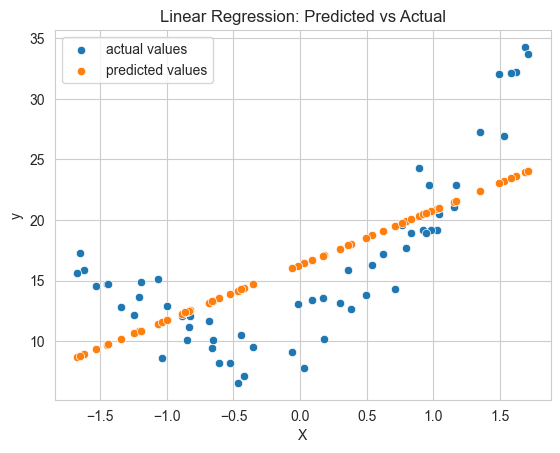

In [57]:

# Exercise 1: Basic Linear Regression
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

rng = np.random.default_rng(42)
X = np.linspace(-3, 5, 300)
y = X**2 + 10  + rng.normal(0, 2, len(X))
X = X[:, np.newaxis]

# Split data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Standardize features
scaler = StandardScaler()
# Learn the rules from training data, then apply them.
X_train_scaled = scaler.fit_transform(X_train)
# Apply the learned rules to new data.
X_test_scaled = scaler.transform(X_test) # We never fit a transformation on test data only transform

# Fit model
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# Predictions
y_pred = model.predict(X_test_scaled)

# Plot predicted vs actual
sns.scatterplot(x=X_test_scaled[:, 0], y=y_test, label='actual values')
sns.scatterplot(x=X_test_scaled[:, 0], y=y_pred, label='predicted values')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.title("Linear Regression: Predicted vs Actual")
plt.show()


## Exercise 2: Exploring the Effect of fit_intercept and copy_X

Fit models with `fit_intercept=True` and `fit_intercept=False`. Compare coefficients and predictions.

✅ fit_intercept=True (default)
- The model learns an intercept term b in the equation:
`y = Xw + b`
- Useful when your features are not centered (i.e., mean ≠ 0).
- Most real-world datasets need this.
-
❌ fit_intercept=False
- The model does not learn an intercept — assumes:
`y = Xw`
- Only appropriate if your data is already centered or you know the intercept should be zero.



Coefficients with intercept: [4.53507918] 16.289564792014406
Coefficients without intercept: [4.53507918] 0.0


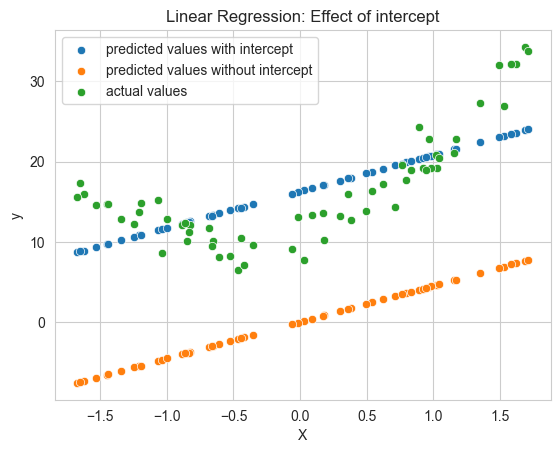

In [58]:

# Exercise 2: Effect of fit_intercept and copy_X
model_true = LinearRegression(fit_intercept=True)
model_false = LinearRegression(fit_intercept=False)

model_true.fit(X_train_scaled, y_train)
model_false.fit(X_train_scaled, y_train)

print("Coefficients with intercept:", model_true.coef_, model_true.intercept_)
print("Coefficients without intercept:", model_false.coef_, model_false.intercept_)

# Predictions
y_pred_true = model_true.predict(X_test_scaled)
y_pred_false = model_false.predict(X_test_scaled)

# Plot predicted vs actual
sns.scatterplot(x=X_test_scaled[:, 0], y=y_pred_true, label='predicted values with intercept')
sns.scatterplot(x=X_test_scaled[:, 0], y=y_pred_false, label='predicted values without intercept')
sns.scatterplot(x=X_test_scaled[:, 0], y=y_test, label='actual values')
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.title("Linear Regression: Effect of intercept")
plt.show()



## Exercise 3: Polynomial Regression

Use `PolynomialFeatures` to add non-linear terms to one variable (degree 2 or 3). Fit and visualize 
how polynomial regression models curvature.

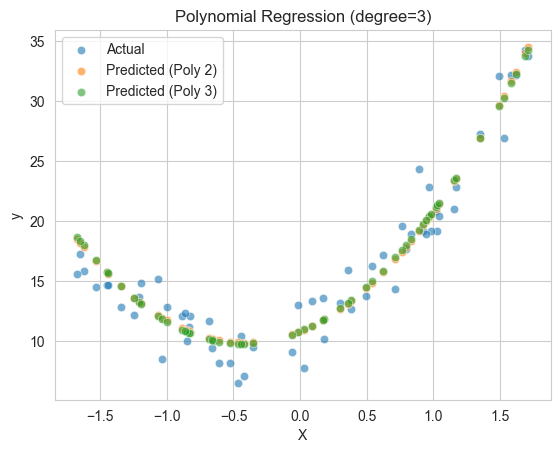

In [59]:

# Exercise 4: Polynomial Regression
from sklearn.preprocessing import PolynomialFeatures

# Expands your input features to include quadratic terms (e.g., x,x^2).
poly_2 = PolynomialFeatures(degree=2, include_bias=False)
X_poly_2 = poly_2.fit_transform(X_train_scaled)
X_poly_2_test = poly_2.transform(X_test_scaled)
# Adds cubic terms (e.g., x,x^2,x^3) for more flexibility
poly_3 = PolynomialFeatures(degree=3, include_bias=False)
X_poly_3 = poly_3.fit_transform(X_train_scaled)
X_poly_3_test = poly_3.transform(X_test_scaled)

model_poly_2 = LinearRegression()
model_poly_2.fit(X_poly_2, y_train)
y_poly_2_pred = model_poly_2.predict(X_poly_2_test)

model_poly_3 = LinearRegression()
model_poly_3.fit(X_poly_3, y_train)
y_poly_3_pred = model_poly_3.predict(X_poly_3_test)

sns.scatterplot(x=X_test_scaled[:, 0], y=y_test, label="Actual", alpha=0.6)
sns.scatterplot(x=X_test_scaled[:, 0], y=y_poly_2_pred, label="Predicted (Poly 2)", alpha=0.6)
sns.scatterplot(x=X_test_scaled[:, 0], y=y_poly_3_pred, label="Predicted (Poly 3)", alpha=0.6)
plt.xlabel("X")
plt.ylabel("y")
plt.legend()
plt.title("Polynomial Regression (degree=3)")
plt.show()


## Exercise 4: Regression Metrics Evaluation

Compute regression metrics (`MAE`, `MAPE`, `RMSE`, and `R²`) for your polynomial regression models to determine which degree is most suitable.


In [60]:

# Exercise 5: Regression Metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error
import numpy as np

mae_poly_2 = mean_absolute_error(y_test, y_poly_2_pred)
rmse_poly_2 = np.sqrt(mean_squared_error(y_test, y_poly_2_pred))
r2_poly_2 = r2_score(y_test, y_poly_2_pred)
mape_poly_2 = mean_absolute_percentage_error(y_test, y_poly_2_pred)

mae_poly_3 = mean_absolute_error(y_test, y_poly_3_pred)
rmse_poly_3 = np.sqrt(mean_squared_error(y_test, y_poly_3_pred))
r2_poly_3 = r2_score(y_test, y_poly_3_pred)
mape_poly_3 = mean_absolute_percentage_error(y_test, y_poly_3_pred)

print(f"Poly 2: MAE: {mae_poly_2:.3f}, MAPE: {mape_poly_2:.3f} RMSE: {rmse_poly_2:.3f}, R²: {r2_poly_2:.3f}")

print(f"Poly 3: MAE: {mae_poly_3:.3f}, MAPE: {mape_poly_3:.3f} RMSE: {rmse_poly_3:.3f}, R²: {r2_poly_3:.3f}")

# A polynomial with degree 2 is the best option due to the lower errors and higher R2 (which makes sense because we used it to generate the data)


Poly 2: MAE: 1.510, MAPE: 0.114 RMSE: 1.833, R²: 0.929
Poly 3: MAE: 1.532, MAPE: 0.115 RMSE: 1.840, R²: 0.928
